# Task 1: Multi-Class Benchmark Classification Pipeline (Iris Dataset)

**Goal:** Build an end-to-end classification pipeline with Scikit-Learn, data normalization, and confusion matrices.




In [15]:
import os
from io import StringIO
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the dataset (Pandas)

In [16]:
IRIS_CSV = """sepal_length,sepal_width,petal_length,petal_width,species
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa
5.4,3.9,1.7,0.4,setosa
4.6,3.4,1.4,0.3,setosa
5.0,3.4,1.5,0.2,setosa
4.4,2.9,1.4,0.2,setosa
4.9,3.1,1.5,0.1,setosa
5.4,3.7,1.5,0.2,setosa
4.8,3.4,1.6,0.2,setosa
4.8,3.0,1.4,0.1,setosa
4.3,3.0,1.1,0.1,setosa
5.8,4.0,1.2,0.2,setosa
5.7,4.4,1.5,0.4,setosa
5.4,3.9,1.3,0.4,setosa
5.1,3.5,1.4,0.3,setosa
5.7,3.8,1.7,0.3,setosa
5.1,3.8,1.5,0.3,setosa
5.4,3.4,1.7,0.2,setosa
5.1,3.7,1.5,0.4,setosa
4.6,3.6,1.0,0.2,setosa
5.1,3.3,1.7,0.5,setosa
4.8,3.4,1.9,0.2,setosa
5.0,3.0,1.6,0.2,setosa
5.0,3.4,1.6,0.4,setosa
5.2,3.5,1.5,0.2,setosa
5.2,3.4,1.4,0.2,setosa
4.7,3.2,1.6,0.2,setosa
4.8,3.1,1.6,0.2,setosa
5.4,3.4,1.5,0.4,setosa
5.2,4.1,1.5,0.1,setosa
5.5,4.2,1.4,0.2,setosa
4.9,3.1,1.5,0.2,setosa
5.0,3.2,1.2,0.2,setosa
5.5,3.5,1.3,0.2,setosa
4.9,3.6,1.4,0.1,setosa
4.4,3.0,1.3,0.2,setosa
5.1,3.4,1.5,0.2,setosa
5.0,3.5,1.3,0.3,setosa
4.5,2.3,1.3,0.3,setosa
4.4,3.2,1.3,0.2,setosa
5.0,3.5,1.6,0.6,setosa
5.1,3.8,1.9,0.4,setosa
4.8,3.0,1.4,0.3,setosa
5.1,3.8,1.6,0.2,setosa
4.6,3.2,1.4,0.2,setosa
5.3,3.7,1.5,0.2,setosa
5.0,3.3,1.4,0.2,setosa
7.0,3.2,4.7,1.4,versicolor
6.4,3.2,4.5,1.5,versicolor
6.9,3.1,4.9,1.5,versicolor
5.5,2.3,4.0,1.3,versicolor
6.5,2.8,4.6,1.5,versicolor
5.7,2.8,4.5,1.3,versicolor
6.3,3.3,4.7,1.6,versicolor
4.9,2.4,3.3,1.0,versicolor
6.6,2.9,4.6,1.3,versicolor
5.2,2.7,3.9,1.4,versicolor
5.0,2.0,3.5,1.0,versicolor
5.9,3.0,4.2,1.5,versicolor
6.0,2.2,4.0,1.0,versicolor
6.1,2.9,4.7,1.4,versicolor
5.6,2.9,3.6,1.3,versicolor
6.7,3.1,4.4,1.4,versicolor
5.6,3.0,4.5,1.5,versicolor
5.8,2.7,4.1,1.0,versicolor
6.2,2.2,4.5,1.5,versicolor
5.6,2.5,3.9,1.1,versicolor
5.9,3.2,4.8,1.8,versicolor
6.1,2.8,4.0,1.3,versicolor
6.3,2.5,4.9,1.5,versicolor
6.1,2.8,4.7,1.2,versicolor
6.4,2.9,4.3,1.3,versicolor
6.6,3.0,4.4,1.4,versicolor
6.8,2.8,4.8,1.4,versicolor
6.7,3.0,5.0,1.7,versicolor
6.0,2.9,4.5,1.5,versicolor
5.7,2.6,3.5,1.0,versicolor
5.5,2.4,3.8,1.1,versicolor
5.5,2.4,3.7,1.0,versicolor
5.8,2.7,3.9,1.2,versicolor
6.0,2.7,5.1,1.6,versicolor
5.4,3.0,4.5,1.5,versicolor
6.0,3.4,4.5,1.6,versicolor
6.7,3.1,4.7,1.5,versicolor
6.3,2.3,4.4,1.3,versicolor
5.6,3.0,4.1,1.3,versicolor
5.5,2.5,4.0,1.3,versicolor
5.5,2.6,4.4,1.2,versicolor
6.1,3.0,4.6,1.4,versicolor
5.8,2.6,4.0,1.2,versicolor
5.0,2.3,3.3,1.0,versicolor
5.6,2.7,4.2,1.3,versicolor
5.7,3.0,4.2,1.2,versicolor
5.7,2.9,4.2,1.3,versicolor
6.2,2.9,4.3,1.3,versicolor
5.1,2.5,3.0,1.1,versicolor
5.7,2.8,4.1,1.3,versicolor
6.3,3.3,6.0,2.5,virginica
5.8,2.7,5.1,1.9,virginica
7.1,3.0,5.9,2.1,virginica
6.3,2.9,5.6,1.8,virginica
6.5,3.0,5.8,2.2,virginica
7.6,3.0,6.6,2.1,virginica
4.9,2.5,4.5,1.7,virginica
7.3,2.9,6.3,1.8,virginica
6.7,2.5,5.8,1.8,virginica
7.2,3.6,6.1,2.5,virginica
6.5,3.2,5.1,2.0,virginica
6.4,2.7,5.3,1.9,virginica
6.8,3.0,5.5,2.1,virginica
5.7,2.5,5.0,2.0,virginica
5.8,2.8,5.1,2.4,virginica
6.4,3.2,5.3,2.3,virginica
6.5,3.0,5.5,1.8,virginica
7.7,3.8,6.7,2.2,virginica
7.7,2.6,6.9,2.3,virginica
6.0,2.2,5.0,1.5,virginica
6.9,3.2,5.7,2.3,virginica
5.6,2.8,4.9,2.0,virginica
7.7,2.8,6.7,2.0,virginica
6.3,2.7,4.9,1.8,virginica
6.7,3.3,5.7,2.1,virginica
7.2,3.2,6.0,1.8,virginica
6.2,2.8,4.8,1.8,virginica
6.1,3.0,4.9,1.8,virginica
6.4,2.8,5.6,2.1,virginica
7.2,3.0,5.8,1.6,virginica
7.4,2.8,6.1,1.9,virginica
7.9,3.8,6.4,2.0,virginica
6.4,2.8,5.6,2.2,virginica
6.3,2.8,5.1,1.5,virginica
6.1,2.6,5.6,1.4,virginica
7.7,3.0,6.1,2.3,virginica
6.3,3.4,5.6,2.4,virginica
6.4,3.1,5.5,1.8,virginica
6.0,3.0,4.8,1.8,virginica
6.9,3.1,5.4,2.1,virginica
6.7,3.1,5.6,2.4,virginica
6.9,3.1,5.1,2.3,virginica
5.8,2.7,5.1,1.9,virginica
6.8,3.2,5.9,2.3,virginica
6.7,3.3,5.7,2.5,virginica
6.7,3.0,5.2,2.3,virginica
6.3,2.5,5.0,1.9,virginica
6.5,3.0,5.2,2.0,virginica
6.2,3.4,5.4,2.3,virginica
5.9,3.0,5.1,1.8,virginica
"""

In [17]:
if os.path.exists("iris.csv"):
    df = pd.read_csv("iris.csv")
else:
    df = pd.read_csv(StringIO(IRIS_CSV))

feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
target_names = list(df['species'].unique())
df['target'] = df['species'].map({n: i for i, n in enumerate(target_names)})
df['target_name'] = df['species']

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nClass distribution:")
print(df['target_name'].value_counts())
df.head()

Shape: (150, 7)
Missing values: 0

Class distribution:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species,target,target_name
0,5.1,3.5,1.4,0.2,setosa,0,setosa
1,4.9,3.0,1.4,0.2,setosa,0,setosa
2,4.7,3.2,1.3,0.2,setosa,0,setosa
3,4.6,3.1,1.5,0.2,setosa,0,setosa
4,5.0,3.6,1.4,0.2,setosa,0,setosa


In [18]:
df[feature_names].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


## 2. Exploratory pairplot (Seaborn)
All 4 Iris features are used.

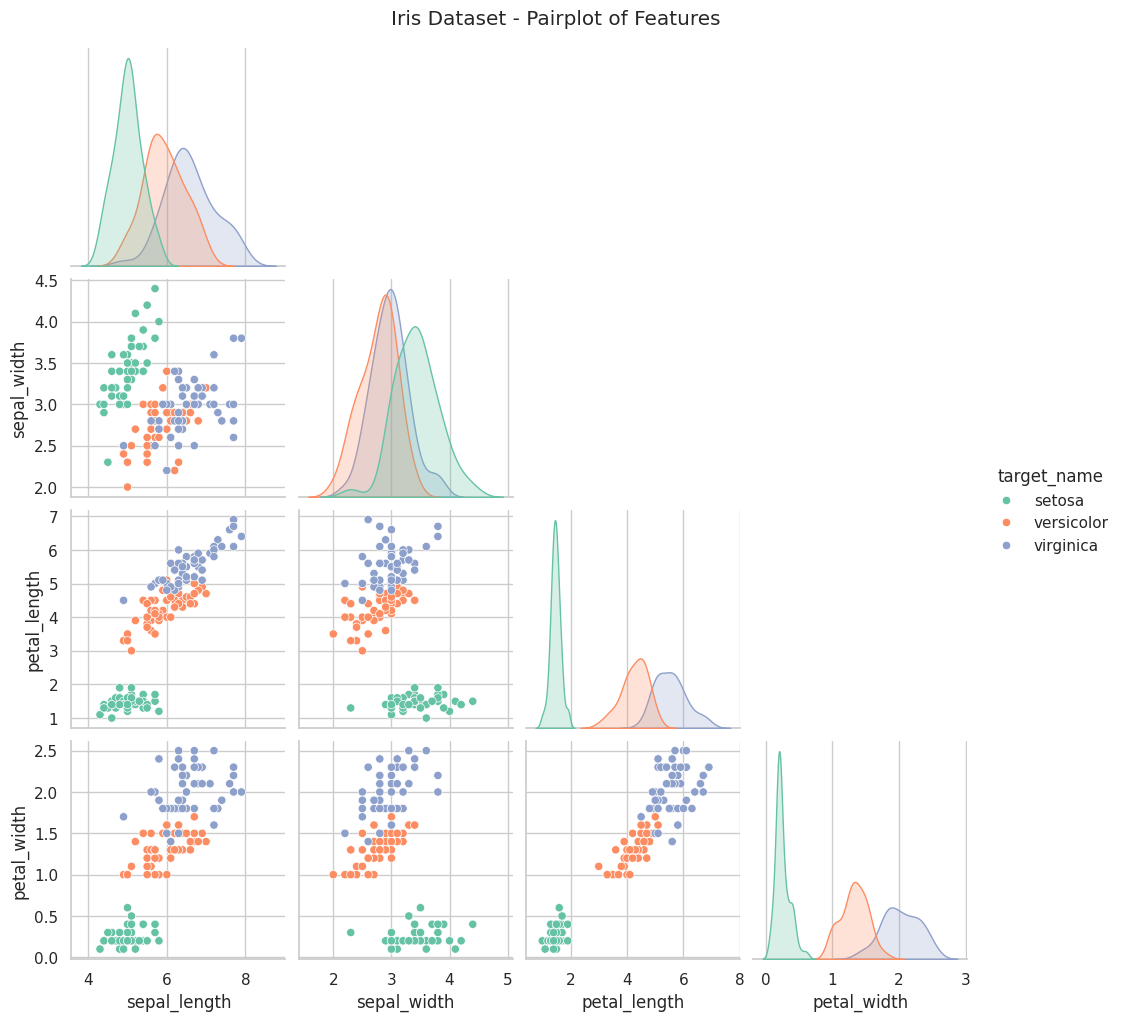

In [19]:
g = sns.pairplot(df, vars=feature_names, hue='target_name', palette='Set2', corner=True, diag_kind='kde')
g.figure.suptitle("Iris Dataset - Pairplot of Features", y=1.02)
plt.show()

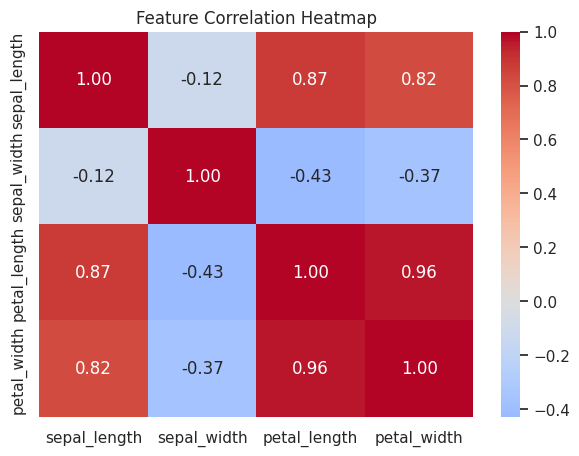

In [20]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[feature_names].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

## 3. Train/Test split (80/20, stratified)

In [21]:
X = df[feature_names]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (120, 4) | Test: (30, 4)


## 4. Feature scaling (StandardScaler)
The scaler is **fit on the training set only** to avoid data leakage.

In [22]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train mean (approx 0):", X_train_s.mean(axis=0).round(2)[:5], "...")
print("Train std  (approx 1):", X_train_s.std(axis=0).round(2)[:5], "...")

Train mean (approx 0): [-0.  0.  0.  0.] ...
Train std  (approx 1): [1. 1. 1. 1.] ...


## 5. Train models

In [23]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
dt_clf = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)

log_reg.fit(X_train_s, y_train)
dt_clf.fit(X_train_s, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": dt_clf}
preds = {name: m.predict(X_test_s) for name, m in models.items()}
print("Models trained.")

Models trained.


## 6. Benchmark: Accuracy, Precision, Recall, F1 (macro-averaged)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


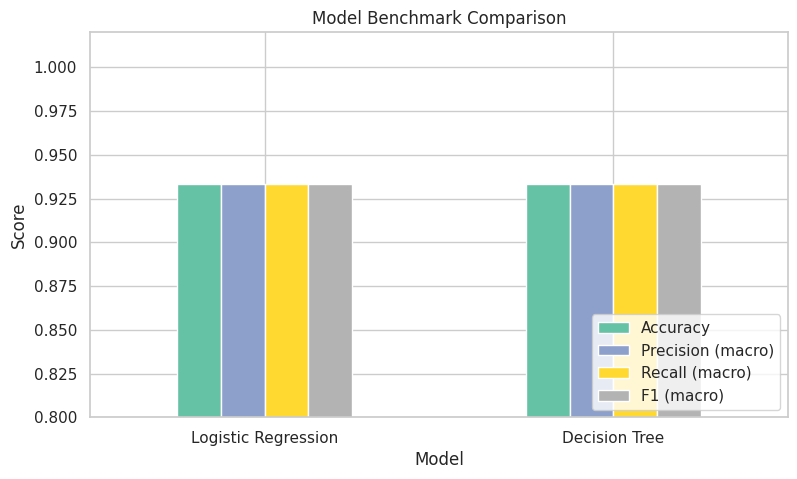

In [24]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average='macro'),
        "Recall (macro)": recall_score(y_test, y_pred, average='macro'),
        "F1 (macro)": f1_score(y_test, y_pred, average='macro'),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

results.plot(kind='bar', figsize=(9, 5), colormap='Set2', rot=0)
plt.ylim(0.8, 1.02); plt.title("Model Benchmark Comparison"); plt.ylabel("Score")
plt.legend(loc='lower right'); plt.show()

### Classification reports (per class)

In [25]:
for name, y_pred in preds.items():
    print("="*60); print(name); print("="*60)
    print(classification_report(y_test, y_pred, target_names=target_names, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



## 7. Confusion matrix heatmaps

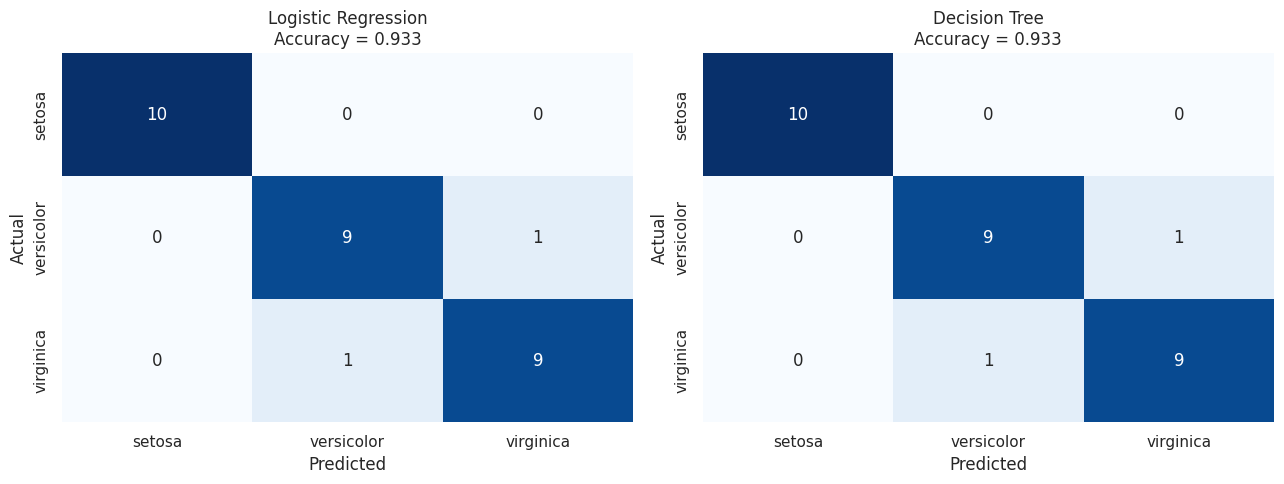

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=target_names, yticklabels=target_names)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

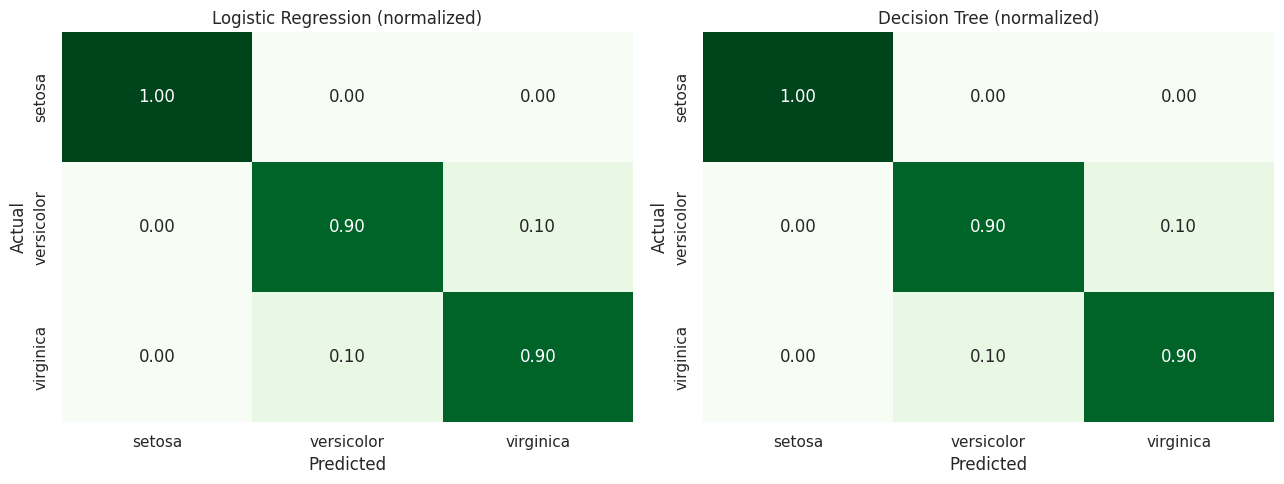

In [27]:
# Normalized (row-wise) confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Greens', cbar=False, ax=ax, vmin=0, vmax=1,
                xticklabels=target_names, yticklabels=target_names)
    ax.set_title(f"{name} (normalized)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 8. Decision boundary visualization
Iris has 4 features, so decision boundaries can't be drawn directly. We project the scaled data to **2 principal components (PCA)** and retrain both models on that 2D space purely for visualization.

Explained variance (PC1, PC2): [0.727 0.231] | total: 0.957


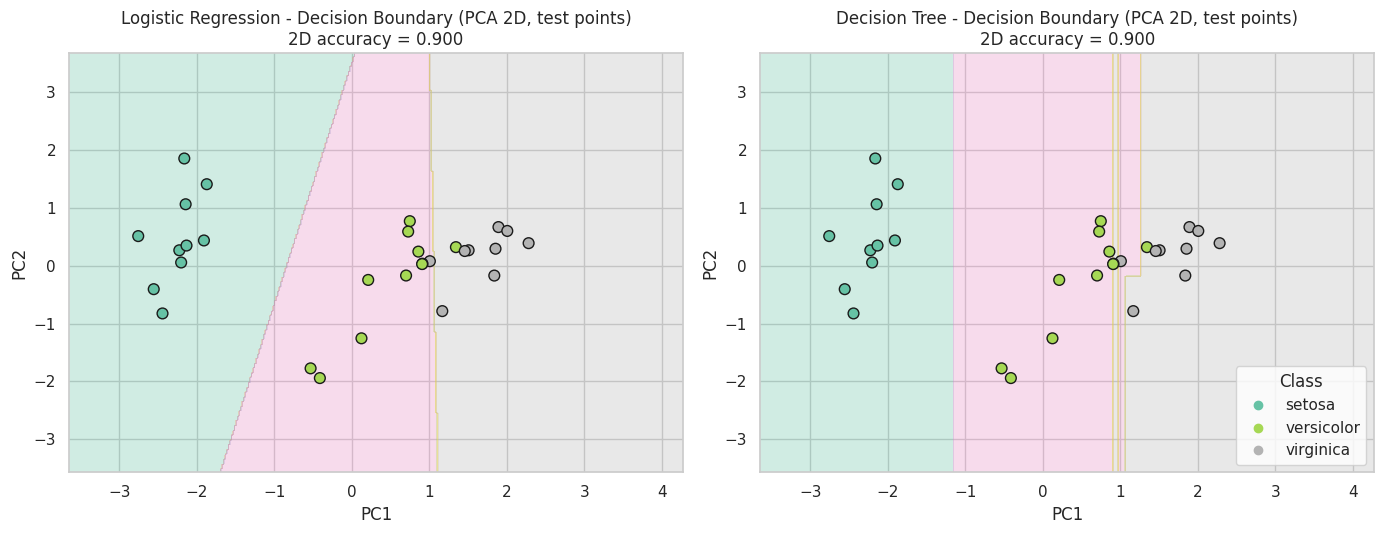

In [28]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xtr_2d = pca.fit_transform(X_train_s)
Xte_2d = pca.transform(X_test_s)
print("Explained variance (PC1, PC2):", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

viz_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}

x_min, x_max = Xtr_2d[:, 0].min() - 1, Xtr_2d[:, 0].max() + 1
y_min, y_max = Xtr_2d[:, 1].min() - 1, Xtr_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, m) in zip(axes, viz_models.items()):
    m.fit(Xtr_2d, y_train)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='Set2')
    sc = ax.scatter(Xte_2d[:, 0], Xte_2d[:, 1], c=y_test, cmap='Set2', edgecolor='k', s=60)
    ax.set_title(f"{name} - Decision Boundary (PCA 2D, test points)\n"
                 f"2D accuracy = {m.score(Xte_2d, y_test):.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
handles, _ = sc.legend_elements()
axes[1].legend(handles, target_names, title="Class", loc='lower right')
plt.tight_layout(); plt.show()